# Book-Crossing recommender: Bronze → Silver → Gold

**Data Mining Lab Assignment — item-based collaborative filtering**

Run all cells in order on a CPU Colab runtime. This notebook downloads the real
[Book-Crossing ZIP](https://cdn.freecodecamp.org/project-data/books/book-crossings.zip),
preserves raw data in Bronze, cleans it in Silver, and reloads Gold artifacts
to recommend books. No API keys, GPU, Drive mount, or local project imports.

**Decisions:** ISBN is the book identifier; ratings 0 are implicit interactions,
not explicit preferences. The model uses explicit ratings and an iterative
10-core. A high rating is ≥8. Results are similarity scores, not predicted ratings.
Different ISBN editions remain distinct items, but recommendations deduplicate
normalized title/author and exclude known editions of already-read works.

The original archive is retained for byte-for-byte source provenance. Source
strings (including `NULL` and empty text) stay unchanged in Bronze; numerical
coercion and semantic null detection happen only in derived EDA views or Silver.

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("google") and importlib.util.find_spec("google.colab"):
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "pandas>=2.2,<4", "numpy>=1.26,<3", "scipy>=1.13,<2",
        "scikit-learn>=1.5,<2", "pyarrow>=17,<30", "matplotlib>=3.8,<4",
    ])

import csv
import hashlib
import io
import json
import os
import platform
import re
import zipfile
from datetime import datetime, timezone
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import Markdown, display
from scipy.sparse import csr_matrix, load_npz, save_npz
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_columns", 12)
ROOT = Path(os.environ.get("BOOK_LAKE_ROOT", "data_lake"))
BRONZE, SILVER, GOLD = [ROOT / name for name in ("bronze", "silver", "gold")]
RAW = ROOT / "raw"
for folder in (RAW, BRONZE, SILVER, GOLD):
    folder.mkdir(parents=True, exist_ok=True)
CURRENT_YEAR = datetime.now(timezone.utc).year
MIN_RATINGS = 10
HIGH_RATING = 8
print("Python", platform.python_version())
print("pandas", pd.__version__, "| NumPy", np.__version__,
      "| SciPy", scipy.__version__, "| scikit-learn", sklearn.__version__)
print("Lake:", ROOT.resolve(), "| year cutoff:", CURRENT_YEAR)

Python 3.12.15
pandas 3.1.1 | NumPy 2.5.5 | SciPy 1.18.1 | scikit-learn 1.9.1
Lake: /home/levi/datamin/submissions/book_crossing_medallion/data_lake | year cutoff: 2026


## Reusable cleaning functions

The filtering loop is important: removing low-activity books can make previously
eligible users fall below the threshold, and vice versa. We stop only at a
fixed point. An empty result is reported rather than relaxing the rule silently.

In [2]:
def clean_ages(raw_age):
    ages = pd.to_numeric(raw_age, errors="coerce")
    ages = ages.where(ages.between(5, 100))
    median = ages.median()
    if pd.isna(median):
        raise ValueError("Cannot impute age: no valid ages remain.")
    return ages.fillna(median), float(median)


def filter_core(ratings, minimum):
    if minimum < 1:
        raise ValueError("minimum must be positive")
    current = ratings.copy()
    history = []
    while True:
        user_counts = current.groupby("user_id").size()
        book_counts = current.groupby("isbn").size()
        keep = (
            current.user_id.isin(user_counts[user_counts >= minimum].index)
            & current.isbn.isin(book_counts[book_counts >= minimum].index)
        )
        filtered = current.loc[keep].copy()
        history.append({
            "iteration": len(history) + 1, "ratings": len(filtered),
            "users": filtered.user_id.nunique(), "books": filtered.isbn.nunique(),
        })
        if len(filtered) == len(current):
            return filtered.reset_index(drop=True), history
        current = filtered


def normalize_text(series):
    return series.astype("string").str.replace(r"\s+", " ", regex=True).str.strip()


def title_key(text):
    return " ".join(str(text).split()).casefold()

## Step 1 — Bronze ingestion

CSV dialect: semicolon separator, Latin-1 encoding, double-quoted fields and
backslash escaping. The backslash escape is necessary for embedded quotes in
this archive. We validate every record's width and never use
`on_bad_lines="skip"`. Parsing the source dialect is not data cleaning.

In [3]:
DATASET_URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
archive_path = RAW / "book-crossings.zip"
if not archive_path.exists():
    request = Request(DATASET_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(request, timeout=120) as response:
        archive_path.write_bytes(response.read())

source_files = {
    "users": "BX-Users.csv",
    "books": "BX-Books.csv",
    "ratings": "BX-Book-Ratings.csv",
}
ingested_at = pd.Timestamp.now(tz="UTC")
ingestion_report = []
with zipfile.ZipFile(archive_path) as archive:
    assert archive.testzip() is None, "Corrupted ZIP"
    for table, filename in source_files.items():
        # Read only the three known members; do not blindly extract the ZIP.
        raw_bytes = archive.read(filename)
        (RAW / filename).write_bytes(raw_bytes)
        records = csv.reader(
            io.StringIO(raw_bytes.decode("latin-1")), delimiter=";", escapechar="\\"
        )
        header = next(records)
        row_count = 0
        for record_number, record in enumerate(records, start=2):
            if len(record) != len(header):
                raise ValueError(f"{filename}, record {record_number}: invalid field count")
            row_count += 1
        frame = pd.read_csv(
            io.BytesIO(raw_bytes), sep=";", encoding="latin-1",
            escapechar="\\", engine="python", dtype="string",
            keep_default_na=False, na_filter=False, on_bad_lines="error",
        )
        assert len(frame) == row_count
        frame["ingestion_timestamp"] = ingested_at
        destination = BRONZE / f"{table}.parquet"
        frame.to_parquet(destination, index=False)
        pd.testing.assert_frame_equal(frame, pd.read_parquet(destination))
        ingestion_report.append({"table": table, "rows": row_count, "columns": len(header)})

manifest = {
    "source_url": DATASET_URL,
    "archive_sha256": hashlib.sha256(archive_path.read_bytes()).hexdigest(),
    "ingestion_timestamp": ingested_at.isoformat(),
    "csv_dialect": {"separator": ";", "encoding": "latin-1", "escapechar": "\\"},
    "tables": ingestion_report,
}
(BRONZE / "manifest.json").write_text(json.dumps(manifest, indent=2))
display(pd.DataFrame(ingestion_report))
print("Archive SHA-256:", manifest["archive_sha256"])

,table,rows,columns
0,users,278858,3
1,books,271379,8
2,ratings,1149780,3


Archive SHA-256: adc7b47afb47c8e29e5f0b70a9816569b3367c5588064ba7a916f16e3ef5d060


## Step 2 — Explore Bronze

Bronze columns intentionally retain source strings, avoiding accidental ISBN
conversion or treating source text as missing during ingestion. Below we show
both actual Parquet null counts and **semantic missingness** (blank/`NULL`/`N/A`
source strings), without modifying Bronze. Numerical views are for EDA only.


users: shape=(278858, 4), exact duplicate rows=0


,dtype,parquet_nulls,semantic_missing
User-ID,string,0,0
Location,string,0,0
Age,string,0,110762
ingestion_timestamp,"datetime64[us, UTC]",0,0



books: shape=(271379, 9), exact duplicate rows=0


,dtype,parquet_nulls,semantic_missing
ISBN,string,0,0
Book-Title,string,0,0
Book-Author,string,0,1
Year-Of-Publication,string,0,0
Publisher,string,0,2
Image-URL-S,string,0,0
Image-URL-M,string,0,0
Image-URL-L,string,0,0
ingestion_timestamp,"datetime64[us, UTC]",0,0



ratings: shape=(1149780, 4), exact duplicate rows=0


,dtype,parquet_nulls,semantic_missing
User-ID,string,0,0
ISBN,string,0,0
Book-Rating,string,0,0
ingestion_timestamp,"datetime64[us, UTC]",0,0


... (4 outputs left out)

,ratings_per_active_user,ratings_per_active_book
count,105283.000000,340556.000000
mean,10.920851,3.376185
std,90.562825,12.436252
min,1.000000,1.000000
50%,1.000000,1.000000
90%,12.000000,6.000000
99%,174.000000,36.000000
max,13602.000000,2502.000000


Users with no raw interactions: 173575


Books with no raw interactions: 1209


Union catalog density: 0.001206%; sparsity: 99.998794%
Metadata-matched density: 0.001363%; sparsity: 99.998637%


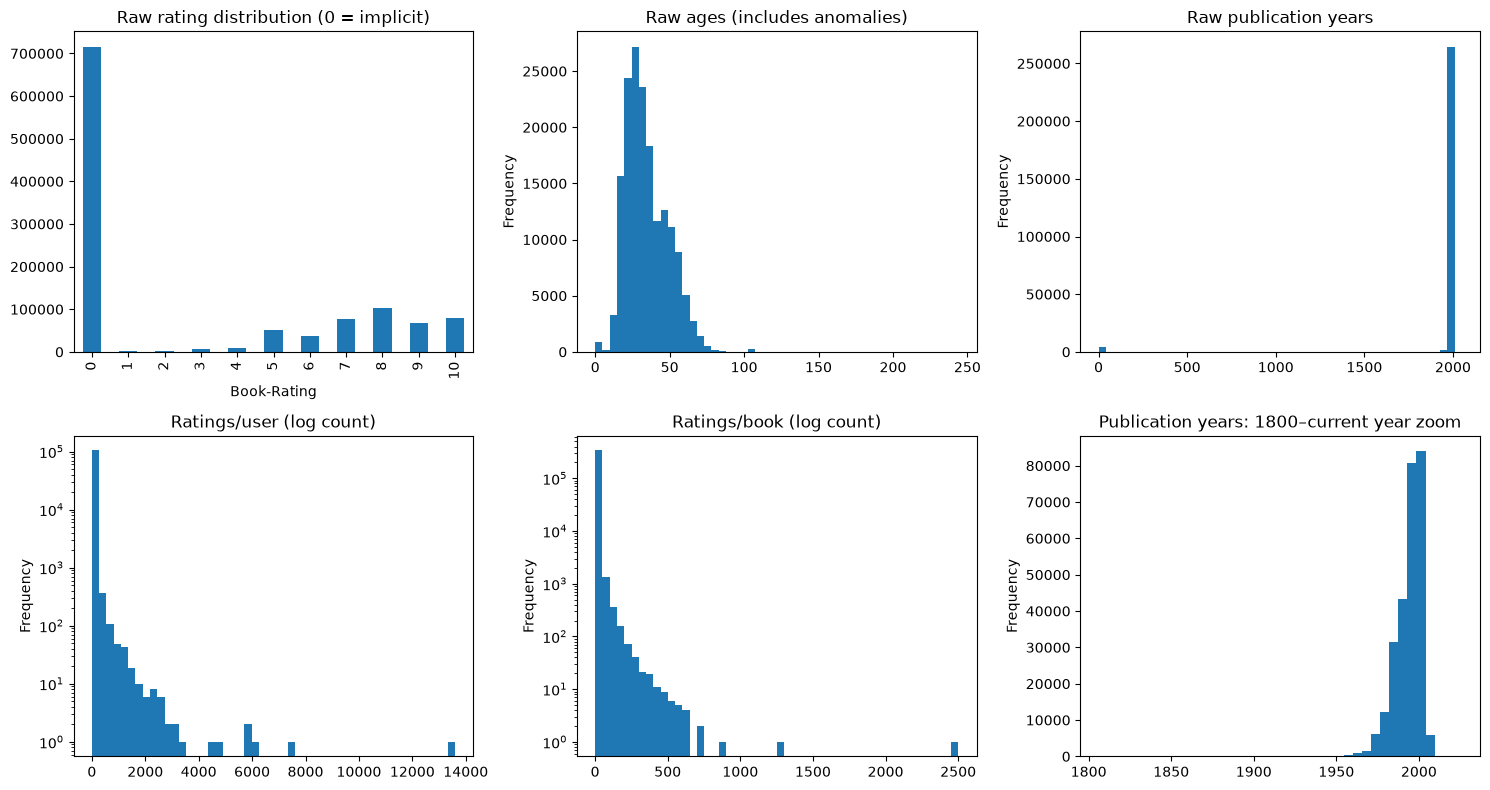

In [4]:
bronze = {name: pd.read_parquet(BRONZE / f"{name}.parquet") for name in source_files}
for name, frame in bronze.items():
    summary = pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "parquet_nulls": frame.isna().sum(),
    })
    semantic = {}
    for column in frame.columns:
        if column != "ingestion_timestamp":
            values = frame[column].str.strip().str.casefold()
            semantic[column] = int(values.isin(["", "null", "n/a", "nan"]).sum())
    summary["semantic_missing"] = pd.Series(semantic).reindex(summary.index).fillna(0).astype(int)
    print(f"\n{name}: shape={frame.shape}, exact duplicate rows={frame.duplicated().sum():,}")
    display(summary)

raw_ratings = pd.to_numeric(bronze["ratings"]["Book-Rating"], errors="coerce")
raw_ages = pd.to_numeric(bronze["users"]["Age"], errors="coerce")
raw_years = pd.to_numeric(bronze["books"]["Year-Of-Publication"], errors="coerce")
rating_counts = raw_ratings.value_counts().sort_index()
display(rating_counts.rename("count").to_frame())
display(pd.DataFrame({
    "age": raw_ages.describe(), "publication_year": raw_years.describe()
}))
print("Missing/nonnumeric ages:", raw_ages.isna().sum())
print("Out-of-range ages:", (raw_ages.notna() & ~raw_ages.between(5, 100)).sum())
print("Invalid years (zero/future/nonnumeric):",
      (raw_years.isna() | raw_years.eq(0) | raw_years.gt(CURRENT_YEAR)).sum())
display(bronze["books"].loc[
    raw_years.isna() | raw_years.eq(0) | raw_years.gt(CURRENT_YEAR),
    ["ISBN", "Book-Title", "Year-Of-Publication"],
].head(10))

raw_user_counts = bronze["ratings"].groupby("User-ID").size()
raw_book_counts = bronze["ratings"].groupby("ISBN").size()
display(pd.DataFrame({
    "ratings_per_active_user": raw_user_counts.describe(percentiles=[.5, .9, .99]),
    "ratings_per_active_book": raw_book_counts.describe(percentiles=[.5, .9, .99]),
}))
print("Users with no raw interactions:",
      (~bronze["users"]["User-ID"].isin(raw_user_counts.index)).sum())
print("Books with no raw interactions:",
      (~bronze["books"]["ISBN"].isin(raw_book_counts.index)).sum())

# Density denominator uses the union catalog, including IDs in ratings that have
# no metadata; also report metadata-matched density to make the scope explicit.
distinct_pairs = bronze["ratings"][["User-ID", "ISBN"]].drop_duplicates()
union_users = pd.Index(bronze["users"]["User-ID"]).union(
    pd.Index(distinct_pairs["User-ID"])
).nunique()
union_books = pd.Index(bronze["books"]["ISBN"]).union(
    pd.Index(distinct_pairs["ISBN"])
).nunique()
raw_density = 100 * len(distinct_pairs) / (union_users * union_books)
matched_pairs = distinct_pairs.loc[
    distinct_pairs["User-ID"].isin(bronze["users"]["User-ID"])
    & distinct_pairs["ISBN"].isin(bronze["books"]["ISBN"])
]
matched_density = 100 * len(matched_pairs) / (
    bronze["users"]["User-ID"].nunique() * bronze["books"]["ISBN"].nunique()
)
print(f"Union catalog density: {raw_density:.6f}%; sparsity: {100 - raw_density:.6f}%")
print(f"Metadata-matched density: {matched_density:.6f}%; "
      f"sparsity: {100 - matched_density:.6f}%")

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
rating_counts.plot.bar(ax=axes[0, 0], title="Raw rating distribution (0 = implicit)")
raw_ages.dropna().plot.hist(bins=50, ax=axes[0, 1], title="Raw ages (includes anomalies)")
raw_years.dropna().plot.hist(bins=50, ax=axes[0, 2], title="Raw publication years")
raw_user_counts.plot.hist(bins=50, logy=True, ax=axes[1, 0], title="Ratings/user (log count)")
raw_book_counts.plot.hist(bins=50, logy=True, ax=axes[1, 1], title="Ratings/book (log count)")
raw_years[raw_years.between(1800, CURRENT_YEAR)].plot.hist(
    bins=40, ax=axes[1, 2], title="Publication years: 1800–current year zoom"
)
fig.tight_layout()
plt.show()

### EDA findings and Silver actions

**Full-data run, UTC year cutoff 2026:** these are observed findings; if the
mirror or year cutoff changes, use the recomputed tables above to update them.

- **Users:** 278,858 × 4 including ingestion time; source fields are strings, timestamp is UTC, no Parquet nulls but 110,762 source ages are missing → parse age and median-impute in Silver.
- **Books:** 271,379 × 9 including ingestion time; source fields are strings, timestamp is UTC, no Parquet nulls but 1 author and 2 publishers are semantically missing → preserve missing metadata as null, normalize text and remove image URLs.
- **Ratings:** 1,149,780 × 4 including ingestion time; source fields are strings, timestamp is UTC, no missing fields or exact duplicate rows → parse ratings/IDs and enforce normalized keys and foreign keys in Silver.
- **Rating distribution:** 716,109 ratings (62.28%) are 0, leaving 433,671 explicit ratings → remove zeros from model training, retain known interactions only for exclusion.
- **Age/year distributions:** ages range 0–244 with 1,248 out of [5,100]; publication years range 0–2050 with 4,630 zero/future/nonnumeric entries → null invalid ages, fill with valid median 32, and null invalid years.
- **Interaction counts:** median active user and median active book each have only 1 raw rating, with 173,575 metadata users and 1,209 metadata books having none → compare thresholds and enforce an iterative 10-core.
- **Matrix sparsity:** union-catalog density is 0.001206% (99.998794% sparse); metadata-matched density is 0.001363% (99.998637% sparse) → remove orphan ratings and use sparse storage, never a dense pivot.

## Step 3 — Silver cleaning

Policies: remove exact duplicates first; for conflicting user/book metadata,
keep the first source record and report counts. For multiple explicit ratings
on the same normalized user–ISBN pair, average them (there is no timestamp to
justify choosing a "latest" rating). ISBNs are stripped and uppercased, not
cast to numbers or constrained to ISBN-10. Titles/authors retain display case,
with casefolded keys for matching; publisher and location fields use lowercase.
Location is split from the right into country/state, leaving extra city commas
in city rather than shifting country. Missing location components remain null.

In [5]:
users = bronze["users"].drop_duplicates().rename(columns={
    "User-ID": "user_id", "Location": "location", "Age": "age",
}).copy()
books = bronze["books"].drop_duplicates().rename(columns={
    "ISBN": "isbn", "Book-Title": "title", "Book-Author": "author",
    "Year-Of-Publication": "publication_year", "Publisher": "publisher",
}).copy()
ratings = bronze["ratings"].drop_duplicates().rename(columns={
    "User-ID": "user_id", "ISBN": "isbn", "Book-Rating": "rating",
}).copy()

users["user_id"] = pd.to_numeric(users.user_id, errors="coerce")
ratings["user_id"] = pd.to_numeric(ratings.user_id, errors="coerce")
cleaned_ids = []
for frame in (users, ratings):
    valid_id = frame.user_id.notna() & frame.user_id.gt(0) & frame.user_id.mod(1).eq(0)
    frame = frame.loc[valid_id].copy()
    frame["user_id"] = frame.user_id.astype("int64")
    cleaned_ids.append(frame)
users, ratings = cleaned_ids

users["age"], median_age = clean_ages(users.age)
users["location"] = normalize_text(users.location).str.casefold()
parts = users.location.str.rsplit(",", n=2, expand=True).reindex(columns=range(3))
for index, column in enumerate(("city", "state", "country")):
    # For incomplete locations retain only the pieces that are actually present.
    users[column] = normalize_text(parts[index]).replace(
        {"": pd.NA, "null": pd.NA, "n/a": pd.NA, "nan": pd.NA}
    )
users = users.drop(columns="location")

books = books.drop(columns=[c for c in books if c.startswith("Image-URL")])
cleaned_isbns = []
for frame in (books, ratings):
    frame = frame.copy()
    frame["isbn"] = normalize_text(frame.isbn).str.upper()
    cleaned_isbns.append(frame.loc[~frame.isbn.isin(["", "NULL"])].copy())
books, ratings = cleaned_isbns
for column in ("title", "author", "publisher"):
    books[column] = normalize_text(books[column]).replace({"": pd.NA, "NULL": pd.NA})
books["publisher"] = books.publisher.str.casefold()
books["title_key"] = books.title.fillna("").map(title_key)
books["author_key"] = books.author.fillna("").map(title_key)
years = pd.to_numeric(books.publication_year, errors="coerce")
books["publication_year"] = years.where(
    years.gt(0) & years.le(CURRENT_YEAR) & years.mod(1).eq(0)
).astype("Int64")
print("Median valid age used for imputation:", median_age)
print("Repeated user IDs:", users.user_id.duplicated().sum(),
      "| repeated normalized ISBNs:", books.isbn.duplicated().sum())
users = users.drop_duplicates("user_id", keep="first")
books = books.drop_duplicates("isbn", keep="first")

ratings["rating"] = pd.to_numeric(ratings.rating, errors="coerce")
ratings = ratings.loc[ratings.rating.between(1, 10)].copy()
print("Explicit ratings before foreign-key filtering:", len(ratings))
ratings = ratings.loc[
    ratings.user_id.isin(users.user_id) & ratings.isbn.isin(books.isbn)
].copy()
print("Explicit metadata-matched ratings:", len(ratings))
print("Repeated user–ISBN pairs:", ratings.duplicated(["user_id", "isbn"]).sum())
ratings = ratings.groupby(["user_id", "isbn"], as_index=False, sort=True).agg(
    rating=("rating", "mean"), ingestion_timestamp=("ingestion_timestamp", "first")
)

# Keep all known raw interactions separately solely as an exclusion list:
# a zero is not a training rating, but indicates an interaction and must not be
# recommended back. This never contributes to similarities or scores.
seen = bronze["ratings"][["User-ID", "ISBN"]].rename(
    columns={"User-ID": "user_id", "ISBN": "isbn"}
).copy()
seen["user_id"] = pd.to_numeric(seen.user_id, errors="coerce")
seen["isbn"] = normalize_text(seen.isbn).str.upper()
seen = seen.loc[seen.user_id.isin(users.user_id) & seen.isbn.isin(books.isbn)]
seen["user_id"] = seen.user_id.astype("int64")
seen = seen.drop_duplicates().reset_index(drop=True)
seen.to_parquet(SILVER / "known_interactions.parquet", index=False)

threshold_comparison = []
for threshold in (5, 10, 15, 20):
    candidate, _ = filter_core(ratings, threshold)
    threshold_comparison.append({
        "minimum": threshold, "users": candidate.user_id.nunique(),
        "books": candidate.isbn.nunique(), "ratings": len(candidate),
        "retained_explicit_pct": 100 * len(candidate) / max(len(ratings), 1),
    })
display(pd.DataFrame(threshold_comparison))
ratings_before_core = len(ratings)
ratings, core_history = filter_core(ratings, MIN_RATINGS)
if ratings.empty:
    raise ValueError("The selected minimum leaves an empty core; review EDA.")
display(pd.DataFrame(core_history))
users = users.loc[users.user_id.isin(ratings.user_id)].sort_values("user_id").reset_index(drop=True)
books = books.loc[books.isbn.isin(ratings.isbn)].sort_values("isbn").reset_index(drop=True)
ratings = ratings.sort_values(["user_id", "isbn"]).reset_index(drop=True)

for name, frame in (("users", users), ("books", books), ("ratings", ratings)):
    frame.to_parquet(SILVER / f"{name}.parquet", index=False)
    pd.testing.assert_frame_equal(frame, pd.read_parquet(SILVER / f"{name}.parquet"))
    print(f"Silver {name}: {frame.shape}")

assert users.user_id.is_unique and books.isbn.is_unique
assert not ratings.duplicated(["user_id", "isbn"]).any()
assert ratings.rating.between(1, 10).all()
assert users.age.between(5, 100).all()
assert books.publication_year.dropna().between(1, CURRENT_YEAR).all()
assert ratings.user_id.isin(users.user_id).all() and ratings.isbn.isin(books.isbn).all()
assert ratings.groupby("user_id").size().min() >= MIN_RATINGS
assert ratings.groupby("isbn").size().min() >= MIN_RATINGS
print("Silver validation passed.")

Median valid age used for imputation: 32.0
Repeated user IDs: 0 | repeated normalized ISBNs: 315


Explicit ratings before foreign-key filtering: 433671


Explicit metadata-matched ratings: 383853
Repeated user–ISBN pairs: 0


,minimum,users,books,ratings,retained_explicit_pct
0,5,6858,9092,115332,30.045877
1,10,1820,2030,41469,10.803354
2,15,0,0,0,0.000000
3,20,0,0,0,0.000000


,iteration,ratings,users,books
0,1,87233,6319,5440
1,2,57938,2655,3277
2,3,48369,2220,2435
3,4,44679,1965,2250
4,5,43043,1896,2131
5,6,42204,1854,2078
6,7,41775,1835,2049
7,8,41604,1824,2041
8,9,41523,1823,2033
9,10,41496,1821,2032


Silver users: (1820, 6)
Silver books: (2030, 8)
Silver ratings: (41469, 4)
Silver validation passed.


### Threshold choice

We use **10 explicit ratings per user and per book after convergence**.
The full-data run retains **1,820 users, 2,030 books and 41,469 ratings**,
or **10.80%** of the 383,853 metadata-matched explicit ratings. Five retains
115,332 ratings (30.05%) but allows weaker support; 15 and 20 collapse to empty
cores. Ten therefore gives a usable, more supported core without the complete
coverage loss of those stricter choices. The trace verifies both axes after
convergence, not just before filtering. The substantial coverage loss is
acknowledged: this model serves the dense core, not the entire original catalog.
It reduces, but does not eliminate, unreliable similarity from small overlaps.
This is a transparent heuristic, not an accuracy-tuned hyperparameter.

## Step 4 — Gold artifacts

Reload Silver to prove the layer boundary. Store CSR ratings with **books as
rows and users as columns**, plus explicit mappings (sorting is deterministic).
A matrix zero now means missing, never an explicit zero rating. Aggregates are
computed from the final Silver core. Age/location/year are retained in Silver
for auditability but are not features of this collaborative-filtering model.

In [6]:
users = pd.read_parquet(SILVER / "users.parquet")
books = pd.read_parquet(SILVER / "books.parquet")
ratings = pd.read_parquet(SILVER / "ratings.parquet")
book_lookup = books[["isbn", "title", "author", "title_key", "author_key"]].copy()
book_lookup.insert(0, "book_idx", np.arange(len(book_lookup)))
user_mapping = users[["user_id"]].copy()
user_mapping.insert(0, "user_idx", np.arange(len(user_mapping)))
indexed = ratings.merge(
    book_lookup[["isbn", "book_idx"]], on="isbn", validate="many_to_one"
).merge(user_mapping, on="user_id", validate="many_to_one")
matrix = csr_matrix((
    indexed.rating.to_numpy(dtype=np.float32),
    (indexed.book_idx.to_numpy(), indexed.user_idx.to_numpy()),
), shape=(len(book_lookup), len(user_mapping)), dtype=np.float32)
save_npz(GOLD / "book_user_ratings.npz", matrix)
book_lookup.to_parquet(GOLD / "book_lookup.parquet", index=False)
user_mapping.to_parquet(GOLD / "user_mapping.parquet", index=False)
user_stats = ratings.groupby("user_id", as_index=False).agg(
    average_rating=("rating", "mean"), rating_count=("rating", "size")
)
book_stats = ratings.groupby("isbn", as_index=False).agg(
    average_rating=("rating", "mean"), rating_count=("rating", "size")
)
user_stats.to_parquet(GOLD / "user_aggregates.parquet", index=False)
book_stats.to_parquet(GOLD / "book_aggregates.parquet", index=False)

# Exclusion titles include metadata for books removed by the core filter too.
all_books = bronze["books"].rename(columns={
    "ISBN": "isbn", "Book-Title": "title", "Book-Author": "author"
})[["isbn", "title", "author"]].copy()
all_books["isbn"] = normalize_text(all_books.isbn).str.upper()
all_books["title_key"] = normalize_text(all_books.title).map(title_key)
all_books["author_key"] = normalize_text(all_books.author).map(title_key)
all_books = all_books.drop_duplicates("isbn")
known = pd.read_parquet(SILVER / "known_interactions.parquet")
known = known.loc[known.user_id.isin(user_mapping.user_id)].merge(
    all_books[["isbn", "title_key", "author_key"]], on="isbn", validate="many_to_one"
)
known.to_parquet(GOLD / "known_interactions.parquet", index=False)
gold_manifest = {
    "orientation": "rows=books, columns=users", "shape": list(matrix.shape),
    "nonzero_ratings": matrix.nnz, "minimum_ratings": MIN_RATINGS,
    "high_rating": HIGH_RATING, "current_year_cutoff": CURRENT_YEAR,
    "source_sha256": manifest["archive_sha256"],
    "versions": {name: module.__version__ for name, module in [
        ("pandas", pd), ("numpy", np), ("scipy", scipy), ("sklearn", sklearn),
    ]},
}
(GOLD / "manifest.json").write_text(json.dumps(gold_manifest, indent=2))
assert matrix.nnz == len(ratings)
assert np.allclose(
    np.asarray(matrix[indexed.book_idx.to_numpy(), indexed.user_idx.to_numpy()]).ravel(),
    indexed.rating.to_numpy(),
)
assert user_stats.rating_count.sum() == book_stats.rating_count.sum() == matrix.nnz
print("Gold shape:", matrix.shape, "| explicit ratings:", matrix.nnz)
print(f"Gold density: {100 * matrix.nnz / np.prod(matrix.shape):.4f}%")
print(f"CSR arrays: {(matrix.data.nbytes + matrix.indices.nbytes + matrix.indptr.nbytes) / 1024**2:.2f} MiB")
display(book_lookup.head())
display(user_stats.head())
display(book_stats.head())

Gold shape: (2030, 1820) | explicit ratings: 41469
Gold density: 1.1224%
CSR arrays: 0.32 MiB


,book_idx,isbn,title,author,title_key,author_key
0,0,0020199600,GREAT GATSBY (REISSUE),F. Scott Fitzgerald,great gatsby (reissue),f. scott fitzgerald
1,1,0020442203,"Lion, the Witch and the Wardrobe",C.S. Lewis,"lion, the witch and the wardrobe",c.s. lewis
2,2,002542730X,Politically Correct Bedtime Stories: Modern Tales for Our Life and Times,James Finn Garner,politically correct bedtime stories: modern tales for our life and times,james finn garner
3,3,0028604199,Once upon a More Enlightened Time: More Politically Correct Bedtime Stories,James Finn Garner,once upon a more enlightened time: more politically correct bedtime stories,james finn garner
4,4,0060002050,On a Wicked Dawn (Cynster Novels),Stephanie Laurens,on a wicked dawn (cynster novels),stephanie laurens


,user_id,average_rating,rating_count
0,243,7.769231,13
1,254,8.45,20
2,638,9.454545,22
3,805,8.4,10
4,882,8.235294,17


,isbn,average_rating,rating_count
0,0020199600,8.166667,12
1,0020442203,8.833333,12
2,002542730X,7.481481,27
3,0028604199,7.9,10
4,0060002050,7.545455,11


## Step 5 — Item-based collaborative filtering

Fit `NearestNeighbors(metric="cosine", algorithm="brute")` directly on sparse
Gold rows. Cosine similarity is `1 − cosine_distance`. We request neighbors on
demand and cache only queried items, never a dense book × book similarity table.

For each seed book rated ≥8, retrieve up to 50 neighbors, discard itself and
zero-similarity items, and accumulate:

$$score(u,j) = \sum_{i \in H_u,\ j \in N_{50}(i)}
   \mathrm{cosine}(i,j)\,\frac{r_{u,i}}{10}.$$

Repeated support from multiple liked books increases score; this is intentionally
not divided by the sum of similarities (which could cancel similarity for one
seed). Exclude every known raw interaction, including implicit zeros, and
equivalent normalized title/author editions. Return up to `n` unique works.
Scores are ranking signals, **not predictions on the 1–10 scale**.

In [7]:
class BookRecommender:
    def __init__(self, matrix, lookup, user_mapping, known=None, neighbor_count=50):
        self.matrix = matrix.tocsr()
        self.lookup = lookup.sort_values("book_idx").reset_index(drop=True).copy()
        self.users = user_mapping.sort_values("user_idx").reset_index(drop=True).copy()
        if self.matrix.shape != (len(self.lookup), len(self.users)):
            raise ValueError("Matrix and mapping shapes disagree")
        if not np.array_equal(self.lookup.book_idx, np.arange(len(self.lookup))):
            raise ValueError("Book indices must be contiguous")
        if not np.array_equal(self.users.user_idx, np.arange(len(self.users))):
            raise ValueError("User indices must be contiguous")
        for column in ("title", "author"):
            self.lookup[f"{column}_key"] = self.lookup[column].fillna("").map(title_key)
        self.user_indices = dict(zip(self.users.user_id, self.users.user_idx))
        self.known = known
        self.neighbor_count = neighbor_count
        self.neighbors = NearestNeighbors(metric="cosine", algorithm="brute", n_jobs=1)
        self.neighbors.fit(self.matrix)
        self.cache = {}

    def _nearest(self, book_idx, n):
        limit = min(n + 1, self.matrix.shape[0])
        cache_key = (book_idx, limit)
        if cache_key not in self.cache:
            distances, indices = self.neighbors.kneighbors(
                self.matrix[book_idx], n_neighbors=limit
            )
            neighbors = [
                (int(index), float(np.clip(1 - distance, 0, 1)))
                for distance, index in zip(distances[0], indices[0])
                if index != book_idx and 1 - distance > 1e-7
            ]
            self.cache[cache_key] = sorted(neighbors, key=lambda pair: (-pair[1], pair[0]))[:n]
        return self.cache[cache_key]

    def similar_books(self, title, n=10, isbn=None):
        if not isinstance(n, int) or n < 0:
            raise ValueError("n must be a nonnegative integer")
        matches = self.lookup.loc[self.lookup.title_key.eq(title_key(title))]
        if isbn is not None:
            matches = matches.loc[matches.isbn.str.upper().eq(str(isbn).strip().upper())]
        if matches.empty:
            raise ValueError(f"Unknown title (or ISBN): {title!r}")
        if len(matches) > 1:
            raise ValueError(f"Ambiguous title; provide isbn from {matches.isbn.tolist()}")
        pairs = self._nearest(int(matches.iloc[0].book_idx), n) if n else []
        rows = self.lookup.iloc[[index for index, _ in pairs]][["isbn", "title", "author"]].copy()
        rows["similarity"] = [similarity for _, similarity in pairs]
        return rows.reset_index(drop=True)

    def profile(self, user_id, high_rating=8):
        if user_id not in self.user_indices:
            raise ValueError(f"Unknown user: {user_id}. No cold-start model is provided.")
        column = self.matrix[:, self.user_indices[user_id]].tocoo()
        rows = self.lookup.iloc[column.row][["isbn", "title", "author"]].copy()
        rows["rating"] = column.data
        return rows.loc[rows.rating.ge(high_rating)].sort_values(
            ["rating", "isbn"], ascending=[False, True]
        ).reset_index(drop=True)

    def recommend(self, user_id, n=10, high_rating=8):
        if not isinstance(n, int) or n < 0:
            raise ValueError("n must be a nonnegative integer")
        if user_id not in self.user_indices:
            raise ValueError(f"Unknown user: {user_id}. No cold-start model is provided.")
        column = self.matrix[:, self.user_indices[user_id]].tocoo()
        read_indices = set(column.row.tolist())
        read_isbns = set(self.lookup.iloc[list(read_indices)].isbn)
        read_works = set(zip(
            self.lookup.iloc[list(read_indices)].title_key,
            self.lookup.iloc[list(read_indices)].author_key,
        ))
        if self.known is not None:
            interactions = self.known.loc[self.known.user_id.eq(user_id)]
            read_isbns.update(interactions.isbn)
            read_works.update(zip(interactions.title_key, interactions.author_key))
        scores = {}
        for seed, rating in zip(column.row, column.data):
            if rating < high_rating:
                continue
            for candidate, similarity in self._nearest(int(seed), self.neighbor_count):
                if candidate not in read_indices:
                    scores[candidate] = scores.get(candidate, 0.0) + similarity * float(rating) / 10
        ranked = sorted(scores, key=lambda index: (-scores[index], self.lookup.iloc[index].isbn))
        accepted, works = [], set()
        for index in ranked:
            book = self.lookup.iloc[index]
            work = (book.title_key, book.author_key)
            if book.isbn in read_isbns or work in read_works or work in works:
                continue
            accepted.append(index)
            works.add(work)
        accepted = accepted[:n]
        result = self.lookup.iloc[accepted][["isbn", "title", "author"]].copy()
        result["score"] = [scores[index] for index in accepted]
        return result.reset_index(drop=True)

In [8]:
# Fresh load: no Silver DataFrames are passed into the model.
gold_matrix = load_npz(GOLD / "book_user_ratings.npz")
gold_books = pd.read_parquet(GOLD / "book_lookup.parquet")
gold_users = pd.read_parquet(GOLD / "user_mapping.parquet")
gold_known = pd.read_parquet(GOLD / "known_interactions.parquet")
model = BookRecommender(gold_matrix, gold_books, gold_users, known=gold_known)


def similar_books(title, n=10, isbn=None):
    return model.similar_books(title, n=n, isbn=isbn)


def recommend(user_id, n=10):
    return model.recommend(user_id, n=n, high_rating=HIGH_RATING)


# Use a real, popular item with an explicit ISBN to avoid edition ambiguity.
popular_isbn = book_stats.sort_values(
    ["rating_count", "isbn"], ascending=[False, True]
).iloc[0].isbn
example_book = gold_books.loc[gold_books.isbn.eq(popular_isbn)].iloc[0]
print("Books similar to:", example_book.title, "| ISBN:", popular_isbn)
display(similar_books(example_book.title, isbn=popular_isbn))

Books similar to: The Lovely Bones: A Novel | ISBN: 0316666343


,isbn,title,author,similarity
0,0446672211,Where the Heart Is (Oprah's Book Club (Paperback)),Billie Letts,0.219241
1,0316096199,Lucky : A Memoir,Alice Sebold,0.217959
2,0385504209,The Da Vinci Code,Dan Brown,0.178328
3,0316601950,The Pilot's Wife : A Novel,Anita Shreve,0.176339
4,0743418174,Good in Bed,Jennifer Weiner,0.175819
5,0446531332,Nights in Rodanthe,Nicholas Sparks,0.170172
6,0688170528,The Pact: A Love Story,Jodi Picoult,0.168194
7,0316603287,The Lake House,James Patterson,0.166218
8,0684857820,Lucky,Alice Sebold,0.165055
9,0316284955,White Oleander : A Novel (Oprah's Book Club),Janet Fitch,0.154238


## Step 6 — Three-user demo and sanity checks

Select reproducibly from three activity bands among users with at least two
highly rated books (not hand-picked for appealing recommendations). Show the
top ten high-rating seeds beside the ten suggestions; report the full seed count.
All high-rated books, not just the displayed ten, contribute to ranking.

In [9]:
high_counts = ratings.loc[ratings.rating.ge(HIGH_RATING)].groupby("user_id").size()
eligible = user_stats.loc[user_stats.user_id.isin(high_counts[high_counts >= 2].index)]
eligible = eligible.sort_values(["rating_count", "user_id"]).reset_index(drop=True)
assert len(eligible) >= 3
positions = [0, len(eligible) // 2, len(eligible) - 1]
demo_user_ids = eligible.iloc[positions].user_id.tolist()
demo_results = {}
for user_id in demo_user_ids:
    profile = model.profile(user_id, high_rating=HIGH_RATING)
    recommendations = recommend(user_id)
    demo_results[str(user_id)] = recommendations.to_dict(orient="records")
    display(Markdown(
        f"### User {user_id}\n"
        f"Explicit ratings: {int(user_stats.loc[user_stats.user_id.eq(user_id), 'rating_count'].iloc[0])}; "
        f"highly rated books: {len(profile)}; recommendations: {len(recommendations)}."
    ))
    side_by_side = pd.concat([
        profile.head(10)[["title", "author", "rating"]].add_prefix("liked_"),
        recommendations[["title", "author", "score"]].add_prefix("recommended_"),
    ], axis=1)
    display(side_by_side)
    known_for_user = gold_known.loc[gold_known.user_id.eq(user_id)]
    assert not recommendations.isbn.isin(known_for_user.isbn).any()
    known_works = set(zip(known_for_user.title_key, known_for_user.author_key))
    recommended_works = [
        (title_key(row.title), title_key(row.author))
        for row in recommendations.itertuples()
    ]
    assert not (set(recommended_works) & known_works)
    assert len(set(recommended_works)) == len(recommended_works)
    assert recommendations.isbn.is_unique
    assert recommendations.score.gt(0).all()
    assert recommendations.score.is_monotonic_decreasing
    assert len(recommendations) == 10, "Demo user has fewer than ten candidates"

(GOLD / "demo_recommendations.json").write_text(
    json.dumps(demo_results, indent=2, ensure_ascii=False)
)
assert gold_matrix.shape == (len(gold_books), len(gold_users))
assert gold_matrix.nnz == len(ratings)
assert np.isfinite(gold_matrix.data).all()
assert gold_matrix.data.min() >= 1 and gold_matrix.data.max() <= 10
assert recommend(demo_user_ids[0], n=0).empty
print("All end-to-end sanity checks passed; demo users:", demo_user_ids)

### User 805
Explicit ratings: 10; highly rated books: 8; recommendations: 10.

,liked_title,liked_author,liked_rating,recommended_title,recommended_author,recommended_score
0,Where the Sidewalk Ends : Poems and Drawings,Shel Silverstein,10.0,Balzac and the Little Chinese Seamstress : A Novel,DAI SIJIE,0.524800
1,Writing Down the Bones,NATALIE GOLDBERG,10.0,Outlander,DIANA GABALDON,0.496852
2,Life of Pi,Yann Martel,9.0,The Temple of My Familiar,Alice Walker,0.492422
3,Interpreter of Maladies,Jhumpa Lahiri,9.0,The Talented Mr. Ripley (Vintage Crime/Black Lizard),Patricia Highsmith,0.481902
4,Dragonfly in Amber,DIANA GABALDON,8.0,Bastard Out of Carolina,Dorothy Allison,0.434880
5,Girl with a Pearl Earring,Tracy Chevalier,8.0,I Know This Much Is True (Oprah's Book Club),Wally Lamb,0.434567
6,JITTERBUG PERFUME,TOM ROBBINS,8.0,Voyager,DIANA GABALDON,0.428171
7,She's Come Undone (Oprah's Book Club (Paperback)),Wally Lamb,8.0,Drums of Autumn,DIANA GABALDON,0.405883
8,<NA>,<NA>,NaN,Charlie and the Chocolate Factory (Puffin Novels),Roald Dahl,0.378791
9,<NA>,<NA>,NaN,The Sweet Potato Queens' Book of Love,JILL CONNER BROWNE,0.377749


### User 143964
Explicit ratings: 16; highly rated books: 15; recommendations: 10.

,liked_title,liked_author,liked_rating,recommended_title,recommended_author,recommended_score
0,Back Roads,Tawni O'Dell,10.0,"Assassins: Assignment: Jerusalem, Target: Antichrist (Left Behind No. 6)",Tim Lahaye,2.828344
1,Left Behind: A Novel of the Earth's Last Days (Left Behind No. 1),Tim Lahaye,10.0,Apollyon: The Destroyer Is Unleashed (Left Behind #5),Tim Lahaye,2.623505
2,Tribulation Force: The Continuing Drama of Those Left Behind (Left Behind No...,Tim LaHaye,10.0,The Remnant: On the Brink of Armageddon (Left Behind No. 10),Tim LaHaye,2.565019
3,The Prayer of Jabez: Breaking Through to the Blessed Life,Bruce Wilkinson,10.0,Armageddon: The Cosmic Battle of the Ages (Left Behind #11),Tim F. LaHaye,2.410337
4,"The Reptile Room (A Series of Unfortunate Events, Book 2)",Lemony Snicket,9.0,The Indwelling: The Beast Takes Possession (Left Behind No. 7),Tim Lahaye,1.877279
5,Fox in Socks (I Can Read It All by Myself Beginner Books),Dr. Seuss,9.0,The Mark: The Beast Rules the World (Left Behind No. 8),Tim Lahaye,1.528391
6,Nicolae: The Rise of Antichrist (Left Behind No. 3),Tim F. Lahaye,9.0,Left Behind: A Novel of the Earth's Last Days (Left Behind #1),Tim Lahaye,1.435512
7,The Mark: The Beast Rules the World (Left Behind #8),Tim LaHaye,9.0,Then Came Heaven,LaVyrle Spencer,1.166633
8,Desecration: Antichrist Takes the Throne (Left Behind No. 9),Tim Lahaye,9.0,What to Expect the First Year,Arlene Eisenberg,1.091955
9,The Book of Questions,Gregory Stock,9.0,The Purpose-Driven Life: What on Earth Am I Here For?,Rick Warren,0.811209


### User 11676
Explicit ratings: 954; highly rated books: 607; recommendations: 10.

,liked_title,liked_author,liked_rating,recommended_title,recommended_author,recommended_score
0,The Poisonwood Bible,Barbara Kingsolver,10.0,"Night Shield (Intimate Moments, 1027)",Nora Roberts,6.633799
1,Daughter of Fortune : A Novel (Oprah's Book Club (Hardcover)),Isabel Allende,10.0,Public Secrets,Nora Roberts,6.360492
2,Prodigal Summer,Barbara Kingsolver,10.0,Birthright,Nora Roberts,5.474627
3,I Know This Much Is True (Oprah's Book Club),Wally Lamb,10.0,Night Tales,Nora Roberts,5.234809
4,The Poisonwood Bible,Barbara Kingsolver,10.0,Tears of the Moon (Irish Trilogy),Nora Roberts,4.976381
5,To Kill a Mockingbird,Harper Lee,10.0,Perfect,Judith McNaught,4.659479
6,Fast Food Nation: The Dark Side of the All-American Meal,Eric Schlosser,10.0,A Perfect Stranger,Danielle Steel,4.470760
7,"The Professor and the Madman: A Tale of Murder, Insanity, and the Making of ...",Simon Winchester,10.0,Tarnished Gold (Landry),V.C. Andrews,4.131156
8,Courting Trouble,Lisa Scottoline,10.0,Born in Shame,Nora Roberts,3.897642
9,The Alchemist: A Fable About Following Your Dream,Paulo Coelho,10.0,The Perfect Neighbor (The Macgregors) (The Macgregors : Special Edition Seri...,Nora Roberts,3.851705


All end-to-end sanity checks passed; demo users: [805, 143964, 11676]


## Interpretation and limitations

- Suggestions are driven by overlap in readers' explicit preferences, not
  title keywords, author labels, age or country. Compare each user's seeds to
  the suggestions above; plausibility alone is not evidence of accuracy.
- This is a functional demo, **not a held-out evaluation**. Training ratings
  also define the displayed profiles. No precision/recall or rating-error
  claims are made; a future experiment should split interactions before
  fitting and evaluate unseen held-out items.
- Ten interactions per item/user does not guarantee ten *common* readers.
  Sparse overlaps and popularity bias can still produce weak similarities;
  overlap shrinkage and minimum common-rater requirements are future options.
- The 10-core excludes most long-tail users/books; new users and books have
  no collaborative signal. Unknown users/titles raise clear errors; users
  with no ≥8 ratings return an empty table rather than an undisclosed fallback.
- Different editions are distinct model rows. Title/author keys suppress
  obvious edition repeats, but cannot reliably identify translations or all
  equivalent works. Unknown metadata also limits this deduplication.
- Missing-year handling follows the assignment (zero/future/nonnumeric);
  unusual historical years are not automatically replaced without evidence.
- Colab storage is ephemeral: download the notebook/outputs or persist the
  generated `data_lake/` separately before ending the runtime. Avoid publishing
  row-level user location/age artifacts unnecessarily.

## References

- [Book-Crossing dataset background](https://www2.informatik.uni-freiburg.de/~cziegler/BX/)
- [Assignment dataset mirror](https://cdn.freecodecamp.org/project-data/books/book-crossings.zip)
- [scikit-learn nearest-neighbors guide](https://scikit-learn.org/stable/modules/neighbors.html)
- [SciPy sparse matrices](https://docs.scipy.org/doc/scipy/reference/sparse.html)